# Auxiliary Operations — SWAP Gate — QISKIT

**Primitive:** the **SWAP gate** as an auxiliary (non-computational, "plumbing") operation
that exchanges the full quantum state of two qubits — used for routing amplitudes between
qubits when a topology or algorithm needs a value to move to a different wire without
touching its value.

To make the swap's effect actually *visible* in the results (rather than just permuting
identical qubits), each qubit is first prepared in a **different** single-qubit state, then
swapped:

$$|\psi\rangle = \text{SWAP}(0,1)\; \Big(R_X(\theta_b)_{1} \otimes R_Y(\theta_a)_{0}\Big)\,|00\rangle$$

If SWAP is implemented correctly, qubit 0's post-swap marginal must equal qubit 1's
pre-swap marginal, and vice versa — this notebook checks that explicitly as a sanity check,
not just visual inspection of a circuit diagram.

### SETUP (identical in both notebooks — do not diverge)
- N_QUBITS = `2`
- Gate sequence: `RY(0.9)(0)`, `RX(1.3)(1)`, `SWAP(0,1)`
- Fixed state-prep angles: `theta_a = 0.9` (RY on qubit 0), `theta_b = 1.3` (RX on qubit 1)
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention). **CUDA-Q is the opposite (qubit 0 = leftmost / MSB) and
  its notebook explicitly reverses every bitstring to match.**
- SHOTS = `10000`, SEED = `42`
- GLOBAL PHASE CONVENTION: normalize so the first amplitude with `abs(amp) > 1e-9`, in
  ascending bitstring order, is rotated to be real and positive
  (`phase = angle(amp)`, multiply whole vector by `exp(-1j*phase)`).
- Basis ordering for matrices/statevectors: `{|00>, |01>, |10>, |11>}` ascending binary.

### Hand-computed expected result (for sanity-check — see final cells)
Probabilities, ascending bitstring order (qubit 0 = rightmost):
```
|00> : 0.513847
|01> : 0.296958
|10> : 0.119902
|11> : 0.069293
```
Structural check (independent of the numbers above): since only SWAP acts after state
prep, `P(|01>)` after the swap must equal `P(|10>)` **before** the swap, and vice versa —
both notebooks verify this algebraically, not just numerically.

**Run all cells top to bottom.**


In [1]:
# Colab / low-RAM friendly install.
# Statevector simulation here only ever holds 2^N_QUBITS=4 complex numbers, so this
# notebook is trivially light on RAM regardless of machine.
!pip install -q qiskit qiskit-aer pylatexenc
# qiskit         -> core circuit building + quantum_info (Statevector, Operator)
# qiskit-aer     -> AerSimulator (statevector + sampling backend)
# pylatexenc     -> required by circuit.draw(output="mpl") for gate label rendering


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.8 MB/s eta 0:00:00


In [2]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

N_QUBITS = 2
THETA_A = 0.9   # RY angle, qubit 0
THETA_B = 1.3   # RX angle, qubit 1
SHOTS = 10000
SEED = 42

print(f"N_QUBITS={N_QUBITS}  THETA_A={THETA_A}  THETA_B={THETA_B}  SHOTS={SHOTS}  SEED={SEED}")


N_QUBITS=2  THETA_A=0.9  THETA_B=1.3  SHOTS=10000  SEED=42


In [3]:
# Build the circuit gate-by-gate.
qc = QuantumCircuit(N_QUBITS, name="AUX_SWAP")

# --- State prep: put qubit 0 and qubit 1 into DIFFERENT states, so the swap is visible ---
qc.ry(THETA_A, 0)   # qubit 0: real-amplitude rotation towards |1>
qc.rx(THETA_B, 1)   # qubit 1: complex-amplitude rotation towards |1> (picks up -i phase)

# --- Auxiliary operation: SWAP the full state of qubit 0 and qubit 1 ---
qc.swap(0, 1)        # exchanges the two qubits' amplitudes -- pure "plumbing", no phase added

print(qc)


     ┌─────────┐   
q_0: ┤ Ry(0.9) ├─X─
     ├─────────┤ │ 
q_1: ┤ Rx(1.3) ├─X─
     └─────────┘   


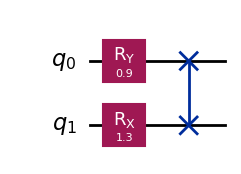

In [4]:
# Draw the circuit with matplotlib and save it.
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.savefig("aux_swap_2q_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# --- Matrix representation, built TWO ways and cross-checked ---

I2 = np.eye(2, dtype=complex)
X_ = np.array([[0, 1], [1, 0]], dtype=complex)
P0 = np.array([[1, 0], [0, 0]], dtype=complex)
P1 = np.array([[0, 0], [0, 1]], dtype=complex)

def RY_(t):
    return np.array([[np.cos(t/2), -np.sin(t/2)],
                      [np.sin(t/2),  np.cos(t/2)]], dtype=complex)

def RX_(t):
    return np.array([[np.cos(t/2), -1j*np.sin(t/2)],
                      [-1j*np.sin(t/2), np.cos(t/2)]], dtype=complex)

# Direct SWAP matrix (basis |00>,|01>,|10>,|11>, little-endian, index = 2*q1+q0)
SWAP_direct = np.array([[1,0,0,0],
                         [0,0,1,0],
                         [0,1,0,0],
                         [0,0,0,1]], dtype=complex)

# (a) Hand-built from individual gate matrices, SAME little-endian kron order used
#     throughout (full_op = kron(op_q1, op_q0)):
U_prep_manual = np.kron(RX_(THETA_B), RY_(THETA_A))
U_full_manual = SWAP_direct @ U_prep_manual

# Independent cross-check of SWAP itself: SWAP == CX(0,1).CX(1,0).CX(0,1)
CX_c0_t1 = np.kron(I2, P0) + np.kron(X_, P1)   # control=qubit0, target=qubit1
CX_c1_t0 = np.kron(P0, I2) + np.kron(P1, X_)   # control=qubit1, target=qubit0
SWAP_from_cx = CX_c0_t1 @ CX_c1_t0 @ CX_c0_t1

max_swap_diff = np.max(np.abs(SWAP_direct - SWAP_from_cx))
print(f"Max abs diff, direct SWAP vs CX-CX-CX decomposition: {max_swap_diff:.2e}")
assert max_swap_diff < 1e-9, "SWAP != CX(0,1).CX(1,0).CX(0,1) decomposition!"
print("SWAP self-consistency check passed.\n")

print("Hand-built full operator (rounded to 4 decimals), basis |00>,|01>,|10>,|11>:")
print(np.round(U_full_manual, 4))

# (b) Framework's own operator extraction
U_full_qiskit = Operator(qc).data
print("\nQiskit Operator(qc) (rounded to 4 decimals):")
print(np.round(U_full_qiskit, 4))

max_op_diff = np.max(np.abs(U_full_manual - U_full_qiskit))
print(f"\nMax abs difference between the two constructions: {max_op_diff:.2e}")
assert max_op_diff < 1e-9, "Manual matrix and Qiskit Operator() disagree!"
print("Matrices match -- safe to use either downstream.")


Max abs diff, direct SWAP vs CX-CX-CX decomposition: 0.00e+00
SWAP self-consistency check passed.

Hand-built full operator (rounded to 4 decimals), basis |00>,|01>,|10>,|11>:
[[ 0.7168+0.j     -0.3463+0.j      0.    -0.5449j  0.    +0.2632j]
 [ 0.    -0.5449j  0.    +0.2632j  0.7168+0.j     -0.3463+0.j    ]
 [ 0.3463+0.j      0.7168+0.j      0.    -0.2632j  0.    -0.5449j]
 [ 0.    -0.2632j  0.    -0.5449j  0.3463+0.j      0.7168+0.j    ]]

Qiskit Operator(qc) (rounded to 4 decimals):
[[ 0.7168+0.j     -0.3463+0.j      0.    -0.5449j  0.    +0.2632j]
 [ 0.    -0.5449j  0.    +0.2632j  0.7168+0.j     -0.3463+0.j    ]
 [ 0.3463+0.j      0.7168+0.j      0.    -0.2632j  0.    -0.5449j]
 [ 0.    -0.2632j  0.    -0.5449j  0.3463+0.j      0.7168+0.j    ]]

Max abs difference between the two constructions: 0.00e+00
Matrices match -- safe to use either downstream.


In [6]:
# --- Exact statevector (no bit-order fix needed for Qiskit) ---
sv = Statevector.from_instruction(qc)
amps = sv.data

idx0 = next(i for i, a in enumerate(amps) if abs(a) > 1e-9)
phase = np.angle(amps[idx0])
amps_norm = amps * np.exp(-1j * phase)

print("Statevector amplitudes (ascending index, qubit 0 = rightmost bit):")
for i, a in enumerate(amps_norm):
    bitstring = format(i, f"0{N_QUBITS}b")
    print(f"  |{bitstring}>: {a.real:+.6f}{a.imag:+.6f}j   prob={abs(a)**2:.6f}")

QISKIT_PROB_DICT = {format(i, f"0{N_QUBITS}b"): float(abs(a)**2) for i, a in enumerate(amps_norm)}
print("\nProbability dict:", QISKIT_PROB_DICT)

# Structural sanity check: prep-only state's P(01)/P(10) should be swapped after SWAP.
qc_prep_only = QuantumCircuit(N_QUBITS)
qc_prep_only.ry(THETA_A, 0)
qc_prep_only.rx(THETA_B, 1)
probs_prep = Statevector.from_instruction(qc_prep_only).probabilities_dict()
print("\nPre-swap probabilities:", {k: round(v,6) for k,v in probs_prep.items()})
assert abs(probs_prep.get("01",0) - QISKIT_PROB_DICT["10"]) < 1e-9
assert abs(probs_prep.get("10",0) - QISKIT_PROB_DICT["01"]) < 1e-9
print("PASS: SWAP correctly exchanged the |01>/|10> probabilities.")


Statevector amplitudes (ascending index, qubit 0 = rightmost bit):
  |00>: +0.716831+0.000000j   prob=0.513847
  |01>: +0.000000-0.544938j   prob=0.296958
  |10>: +0.346269+0.000000j   prob=0.119902
  |11>: +0.000000-0.263235j   prob=0.069293

Probability dict: {'00': 0.5138471838172555, '01': 0.29695780031807684, '10': 0.11990223049503834, '11': 0.06929278536962946}

Pre-swap probabilities: {np.str_('00'): np.float64(0.513847), np.str_('01'): np.float64(0.119902), np.str_('10'): np.float64(0.296958), np.str_('11'): np.float64(0.069293)}
PASS: SWAP correctly exchanged the |01>/|10> probabilities.


### Ordering-fix note

**Qiskit needs no reversal.** Qiskit's `Statevector`/`Operator`/`get_counts()` already
index amplitudes and bitstrings with **qubit 0 as the least-significant (rightmost) bit**,
matching the SETUP contract above. This cell exists only to make that explicit, for
comparison against the CUDA-Q notebook (where a reversal *is* required).


In [7]:
# --- Sampling / measurement ---
qc_meas = qc.copy()
qc_meas.measure_all()

sim = AerSimulator(seed_simulator=SEED)
qc_t = transpile(qc_meas, sim)
result = sim.run(qc_t, shots=SHOTS, seed_simulator=SEED).result()
counts = result.get_counts()

# Qiskit's get_counts() keys are already qubit-0-rightmost -- no reordering needed.
counts_probs = {k: v / SHOTS for k, v in counts.items()}
print("Raw counts:", counts)
print("Sampled probabilities:", counts_probs)


Raw counts: {'11': 660, '01': 3055, '00': 5060, '10': 1225}
Sampled probabilities: {'11': 0.066, '01': 0.3055, '00': 0.506, '10': 0.1225}


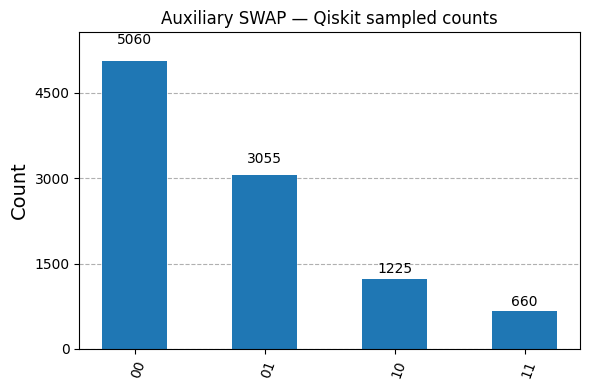

In [8]:
# --- Histogram ---
fig2 = plot_histogram(counts, figsize=(6, 4), title="Auxiliary SWAP — Qiskit sampled counts")
fig2.savefig("aux_swap_2q_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# --- Resource counts ---
print("Depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))


Depth: 2
Gate counts: {'ry': 1, 'rx': 1, 'swap': 1}


### Convention notes (plain text)

- **Bit ordering:** qubit 0 = rightmost bit everywhere in this notebook. This is Qiskit's
  native convention, so no reversal was applied.
- **Global phase:** the statevector was rotated so the amplitude of the first nonzero
  basis state in ascending bitstring order (`|00>` here) is real and positive, before
  reporting amplitudes or comparing to CUDA-Q.
- **Auxiliary operation:** SWAP adds no phase and no entanglement of its own -- it is a
  pure permutation of the two qubits' amplitudes, confirmed above both algebraically
  (matrix form) and structurally (the P(01)/P(10) exchange check).


In [10]:
# --- Final result dict ---
QISKIT_RESULT = QISKIT_PROB_DICT
print("QISKIT_RESULT =", QISKIT_RESULT)

import json
with open("qiskit_result.json", "w") as f:
    json.dump(QISKIT_RESULT, f)
print("\nSaved to qiskit_result.json (the CUDA-Q notebook's diff-check cell can load this")
print("if both notebooks are run in the same working directory / Colab session).")


QISKIT_RESULT = {'00': 0.5138471838172555, '01': 0.29695780031807684, '10': 0.11990223049503834, '11': 0.06929278536962946}

Saved to qiskit_result.json (the CUDA-Q notebook's diff-check cell can load this
if both notebooks are run in the same working directory / Colab session).


In [11]:
# --- Diff-check against CUDA-Q result ---
import json, os

HAND_COMPUTED_EXPECTED = {
    "00": 0.513847, "01": 0.296958, "10": 0.119902, "11": 0.069293,
}

max_delta_hand = max(abs(QISKIT_RESULT[k] - HAND_COMPUTED_EXPECTED[k]) for k in QISKIT_RESULT)
print(f"Max |QISKIT_RESULT - hand-computed expected| = {max_delta_hand:.2e}")
assert max_delta_hand < 1e-3, "Qiskit result does not match the hand-computed expectation!"
print("PASS: Qiskit result matches the hand-computed expectation within 1e-3.\n")

if os.path.exists("cudaq_result.json"):
    with open("cudaq_result.json") as f:
        CUDAQ_RESULT = json.load(f)
    max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT.get(k, float("nan"))) for k in QISKIT_RESULT)
    print(f"Max |QISKIT_RESULT - CUDAQ_RESULT| = {max_delta:.2e}")
    assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree by more than 1e-3!"
    print("PASS: Qiskit and CUDA-Q results match within 1e-3.")
else:
    print("cudaq_result.json not found yet -- run the CUDA-Q notebook in this same")
    print("working directory (it saves cudaq_result.json), then re-run this cell.")


Max |QISKIT_RESULT - hand-computed expected| = 2.30e-07
PASS: Qiskit result matches the hand-computed expectation within 1e-3.

cudaq_result.json not found yet -- run the CUDA-Q notebook in this same
working directory (it saves cudaq_result.json), then re-run this cell.
